# Chapter 10 — Intro to Convolutional Neural Networks: Learning Edges and Corners

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 10, explain every theory, and reproduce the code (a convolutional layer built from scratch with NumPy).

> ⚙️ **Dataset note:** same offline `load_digits` set as Chapters 8-9 (8×8 images + σ = 0.35 noise, 300 training / 1 497 test images). Because the images are 8×8 we use **3×3 kernels** that produce a **6×6** grid of positions (the book uses 3×3 kernels on 28×28 MNIST → 26×26 positions). The code is otherwise the same idea.

---

## 1. Chapter Summary

1. **Reusing weights in multiple places.** A dense network learns a *separate* weight for each pixel/neuron pair, so a feature (say, a vertical edge) must be learned *again* at every position. A **convolutional layer** learns a *small detector* once and **re-uses it at every location** of the image.
2. **The convolutional layer.** A small **kernel** (e.g. 3×3 = 9 weights) is slid over the image; at each position the dot-product of kernel and image patch gives one output number. The result for one kernel is a *feature map*.
3. **Why it counters overfitting.** Far fewer weights (a 3×3 kernel has 9 weights vs. 64×N for a dense layer) and the *structure* is built into the model (**translation invariance**: an edge is an edge wherever it is). Weight sharing is a *regularizer* — the network can't memorise position-specific quirks.
4. **Many kernels.** One kernel detects one pattern (e.g. horizontal edge). Using *several* kernels (feature maps) lets the layer detect edges at different orientations, corners, curves, ... The output of the conv layer is a stack of feature maps.
5. **Implementation (book):**
   1. `get_image_section(layer, row_from, row_to, col_from, col_to)` extracts patches.
   2. Stack all patches into `expanded_input` (positions × 9).
   3. Multiply by the shared `kernels` matrix (9 × n_kernels).
   4. Flatten the feature maps and feed them to a normal dense softmax layer.
   5. Back-propagate: the delta of the conv output is reshaped and multiplied by the *expanded* input to update the shared kernels.
6. **Result:** in our run the CNN ends with a higher final test accuracy than the fully-connected network (about +3 to +4 points) while using roughly **7× fewer parameters**; the best-epoch accuracies are close, so the main win is stability and efficiency rather than a huge accuracy jump on this tiny dataset.
7. **Foundation of modern vision models:** later layers can convolve over feature maps to get edges → corners → shapes → objects.

---

## 2. Theory Deep-Dive

### 2.1 Convolution (cross-correlation) in 2-D
For image $I$ and kernel $K$ of size $k\times k$:
$$\text{out}[i,j]=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K[u,v]\;I[i+u,\,j+v]$$
Output size (no padding, stride 1): $(H-k+1)\times(W-k+1)$ → for $8\times8$ and $k=3$: $6\times6=36$ positions.

### 2.2 Weight sharing = same dot product at every position
Equivalent matrix form: stack all 36 patches as rows → `patches` has shape `(36, 9)`; `kernels` has shape `(9, K)`:

$$\text{feature maps}=\text{patches}\;\cdot\;\text{kernels}\ \in\mathbb R^{36\times K}$$

**Parameter counting** (our toy case, K = 8 kernels):

| Layer | Weights |
|---|---|
| Dense 64 → 288 (to get the same 36×8 outputs) | 64 × 288 = **18 432** |
| Conv 3×3, 8 kernels | 9 × 8 = **72** |

### 2.3 Why edges and corners?
A kernel like $\begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix}$ responds strongly to a *vertical edge* and ≈0 elsewhere. Learning kernels with gradient descent means the network *discovers* its own edge/corner/curve detectors, since they are the correlations (Ch. 7) that help predict the label.

### 2.4 Backpropagation through a convolutional layer
Forward (per image, per position $p$, per kernel $k$): $c_{p,k}=\text{patch}_p\cdot K_{:,k}$, $h=\tanh(c)$.

* Delta arriving at the conv output (after the dense layer's back-prop): $d_{p,k}$.
* Since the *same* kernel was used at all positions, **its gradient is the sum over all positions**:
$$\frac{\partial L}{\partial K}=\sum_p \text{patch}_p^{T}\,d_{p,:}$$
In code: `kernels -= alpha * expanded_input.reshape(-1, 9).T @ delta.reshape(-1, K)`.

### 2.5 Pooling and deeper stacks (beyond the book's code)
Real CNNs add **pooling** (down-sample feature maps) and **multiple conv layers**, so higher layers see larger regions. Chapter 10's lesson is the *principle*: **put structure into the network so it generalises**.

---

## 3. Code Reproduction

### 3.1 Data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.datasets import load_digits
os.makedirs("folder-picture", exist_ok=True)

digits = load_digits()
X_all = digits.data / 16.0
y_all = digits.target
X_all = np.clip(X_all + np.random.default_rng(5).normal(0, 0.35, X_all.shape), 0, 1)

perm = np.random.default_rng(0).permutation(len(X_all))
N_TRAIN = 300
tr, te = perm[:N_TRAIN], perm[N_TRAIN:]
x_train, y_train = X_all[tr], y_all[tr]
x_test,  y_test  = X_all[te], y_all[te]
labels_train = np.eye(10)[y_train]
print("train", x_train.shape, " test", x_test.shape)

def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

train (300, 64)  test (1497, 64)


### 3.2 Extracting image sections (the book's `get_image_section`) and a hand-made edge detector

patches per image: (1, 36, 9)  -> 6x6 = 36 positions, 9 pixels each


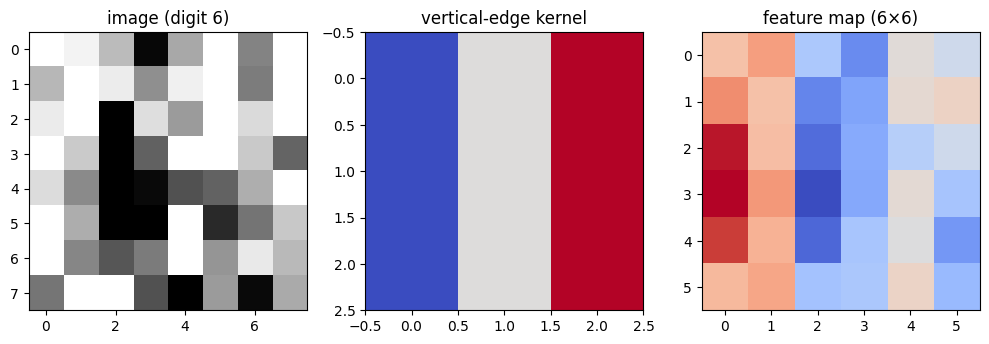

In [2]:
def get_image_section(layer, row_from, row_to, col_from, col_to):
    """layer: (batch, H, W) -> (batch, 1, row_to-row_from, col_to-col_from)"""
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to - row_from, col_to - col_from)

def expand_input(images, k=3):
    """(batch, 64) -> (batch, n_positions, k*k): every k×k patch, flattened."""
    imgs = images.reshape(-1, 8, 8)
    H = 8 - k + 1
    sects = [get_image_section(imgs, r, r + k, c, c + k) for r in range(H) for c in range(H)]
    expanded = np.concatenate(sects, axis=1)                  # (batch, 36, k, k)
    return expanded.reshape(len(images), -1, k * k)           # (batch, 36, 9)

patches = expand_input(x_train[:1])
print("patches per image:", patches.shape, " -> 6x6 = 36 positions, 9 pixels each")

# a hand-designed vertical-edge kernel applied everywhere = the convolution
vertical_edge = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]).reshape(9, 1)
fmap = (patches[0] @ vertical_edge).reshape(6, 6)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(x_train[0].reshape(8, 8), cmap="gray_r"); ax[0].set_title(f"image (digit {y_train[0]})")
ax[1].imshow(vertical_edge.reshape(3, 3), cmap="coolwarm"); ax[1].set_title("vertical-edge kernel")
ax[2].imshow(fmap, cmap="coolwarm"); ax[2].set_title("feature map (6×6)")
plt.tight_layout()
plt.savefig("folder-picture/ch10_convolution_demo.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.3 The convolutional network (kernels shared across all positions)

Architecture: `image (8×8) → 3×3 conv, K kernels (tanh) → flatten (36·K) → dropout → dense softmax (10)`.

In [3]:
tanh2deriv = lambda o: 1 - o ** 2

K = 8                                   # number of kernels (feature maps)
X_train_exp = expand_input(x_train)     # (300, 36, 9) — computed once
X_test_exp  = expand_input(x_test)      # (1497, 36, 9)
n_pos = X_train_exp.shape[1]

def forward(exp_input, kernels, W1):
    B = len(exp_input)
    conv = exp_input.reshape(-1, 9) @ kernels                  # (B*36, K)  shared kernels!
    l1 = np.tanh(conv.reshape(B, -1))                          # (B, 36*K)
    return l1, softmax(l1 @ W1)

def train_cnn(batch_size=20, alpha=0.1, epochs=100, seed=1):
    r = np.random.default_rng(seed)
    kernels = 0.02 * r.random((9, K)) - 0.01
    W1 = 0.2 * r.random((n_pos * K, 10)) - 0.1
    tr_acc, te_acc, losses = [], [], []
    for epoch in range(epochs):
        ep_loss = 0.0
        for s in range(0, N_TRAIN, batch_size):
            exp_in = X_train_exp[s:s + batch_size]
            y = labels_train[s:s + batch_size]
            B = len(exp_in)
            conv = exp_in.reshape(-1, 9) @ kernels
            l1 = np.tanh(conv.reshape(B, -1))
            mask = r.integers(0, 2, size=l1.shape) * 2          # dropout
            l1d = l1 * mask
            l2 = softmax(l1d @ W1)
            ep_loss += -np.sum(y * np.log(l2 + 1e-12))

            d2 = (l2 - y) / B
            d1 = (d2 @ W1.T) * tanh2deriv(l1) * mask             # delta at conv output (B, 36*K)
            W1 -= alpha * l1d.T @ d2
            # gradient of the SHARED kernels = sum over positions & images
            kernels -= alpha * exp_in.reshape(-1, 9).T @ d1.reshape(-1, K)
        tr_acc.append((forward(X_train_exp, kernels, W1)[1].argmax(1) == y_train).mean())
        te_acc.append((forward(X_test_exp,  kernels, W1)[1].argmax(1) == y_test).mean())
        losses.append(ep_loss / N_TRAIN)
    return np.array(tr_acc), np.array(te_acc), np.array(losses), kernels, W1

tr_c, te_c, loss_c, kernels, W1c = train_cnn()
print(f"CNN : train acc {tr_c[-1]:.3f} | test acc {te_c[-1]:.3f} | cross-entropy {loss_c[-1]:.4f}")
print("conv parameters:", kernels.size, " | dense-output parameters:", W1c.size)

CNN : train acc 0.997 | test acc 0.779 | cross-entropy 0.1815
conv parameters: 72  | dense-output parameters: 2880


### 3.4 Baseline — the fully-connected tanh+softmax network from Chapter 9

(Same data, same hidden width ≈ comparable, same dropout / batch size / alpha.)

In [4]:
def train_dense(batch_size=20, alpha=0.1, hidden=288, epochs=100, seed=1):
    r = np.random.default_rng(seed)
    W0 = 0.02 * r.random((64, hidden)) - 0.01
    W1 = 0.2  * r.random((hidden, 10)) - 0.1
    tr_acc, te_acc = [], []
    for epoch in range(epochs):
        for s in range(0, N_TRAIN, batch_size):
            l0 = x_train[s:s + batch_size]; y = labels_train[s:s + batch_size]
            l1 = np.tanh(l0 @ W0)
            mask = r.integers(0, 2, size=l1.shape) * 2
            l1d = l1 * mask
            l2 = softmax(l1d @ W1)
            d2 = (l2 - y) / len(l0)
            d1 = (d2 @ W1.T) * tanh2deriv(l1) * mask
            W1 -= alpha * l1d.T @ d2
            W0 -= alpha * l0.T @ d1
        tr_acc.append(((np.tanh(x_train @ W0) @ W1).argmax(1) == y_train).mean())
        te_acc.append(((np.tanh(x_test  @ W0) @ W1).argmax(1) == y_test).mean())
    return np.array(tr_acc), np.array(te_acc), (W0, W1)

seeds = (1, 2, 3)
cnn_runs   = [train_cnn(seed=s) for s in seeds]
dense_runs = [train_dense(seed=s) for s in seeds]
te_cnn   = np.mean([r[1] for r in cnn_runs], axis=0)
te_dense = np.mean([r[1] for r in dense_runs], axis=0)

print(f"Dense net (hidden 288): params {64*288 + 288*10:6d} | final test acc {te_dense[-1]:.3f} | best {te_dense.max():.3f}")
print(f"CNN (3×3, {K} kernels) : params {9*K + n_pos*K*10:6d} | final test acc {te_cnn[-1]:.3f} | best {te_cnn.max():.3f}")

Dense net (hidden 288): params  21312 | final test acc 0.745 | best 0.780
CNN (3×3, 8 kernels) : params   2952 | final test acc 0.781 | best 0.786


### 3.5 Visualising results and the learned kernels

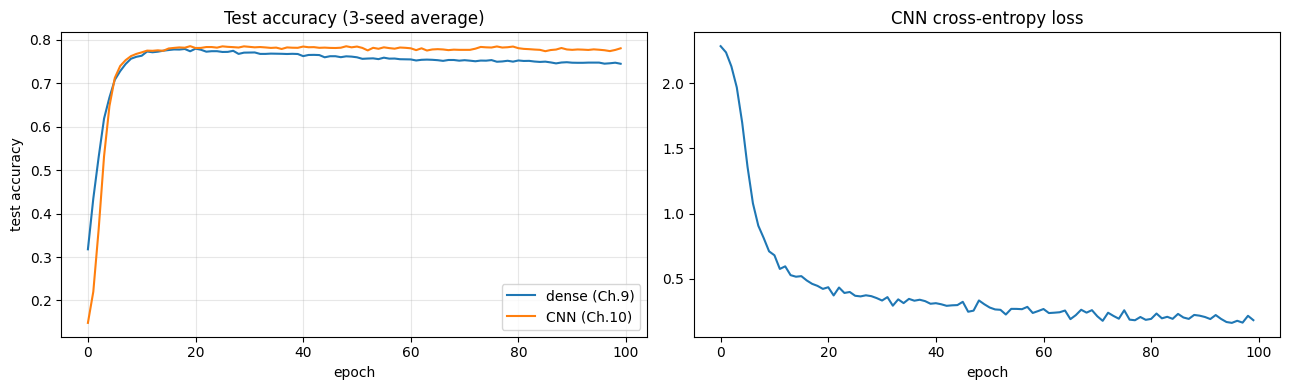

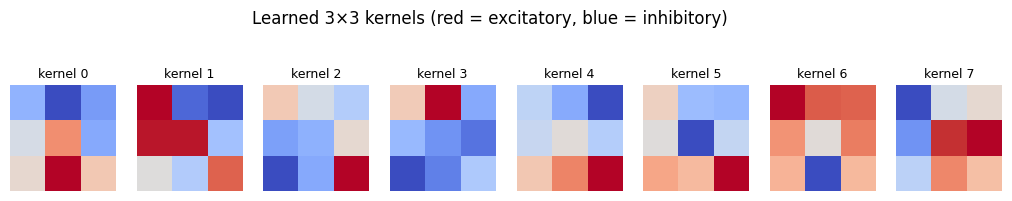

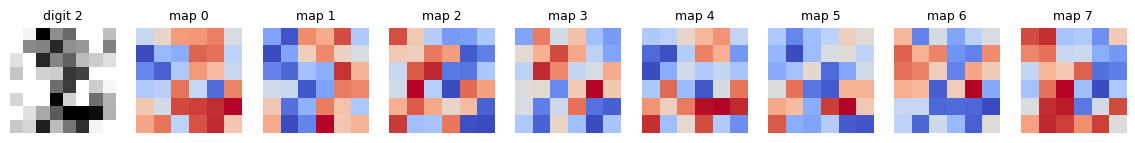

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(te_dense, label="dense (Ch.9)"); ax[0].plot(te_cnn, label="CNN (Ch.10)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("test accuracy"); ax[0].grid(alpha=.3); ax[0].legend()
ax[0].set_title("Test accuracy (3-seed average)")
ax[1].plot(loss_c); ax[1].set_title("CNN cross-entropy loss"); ax[1].set_xlabel("epoch")
plt.tight_layout()
plt.savefig("folder-picture/ch10_cnn_vs_dense.png", dpi=120, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(1, K, figsize=(1.6 * K, 2.2))
for k in range(K):
    ax[k].imshow(kernels[:, k].reshape(3, 3), cmap="coolwarm"); ax[k].set_title(f"kernel {k}", fontsize=9); ax[k].axis("off")
plt.suptitle("Learned 3×3 kernels (red = excitatory, blue = inhibitory)", y=1.08)
plt.savefig("folder-picture/ch10_learned_kernels.png", dpi=120, bbox_inches="tight")
plt.show()

# feature maps of one test image
exp1 = X_test_exp[:1]
fm = np.tanh(exp1.reshape(-1, 9) @ kernels).reshape(6, 6, K)
fig, ax = plt.subplots(1, K + 1, figsize=(1.6 * (K + 1), 2.2))
ax[0].imshow(x_test[0].reshape(8, 8), cmap="gray_r"); ax[0].set_title(f"digit {y_test[0]}", fontsize=9); ax[0].axis("off")
for k in range(K):
    ax[k + 1].imshow(fm[:, :, k], cmap="coolwarm"); ax[k + 1].set_title(f"map {k}", fontsize=9); ax[k + 1].axis("off")
plt.savefig("folder-picture/ch10_feature_maps.png", dpi=120, bbox_inches="tight")
plt.show()

Each learned kernel is a tiny **pattern detector** (some respond to strokes of a given orientation, others to bright/dark blobs); the feature maps show *where* in the image each pattern fires. The dense layer on top combines these "evidence maps" to decide which digit it is.

---

## 4. Key Takeaways

* A **convolutional layer** applies the *same small kernel at every position* — weight sharing builds *translation invariance* into the model.
* It needs **far fewer weights** and is a strong, structure-based **regularizer** (fights overfitting).
* **Multiple kernels** = multiple feature maps (edges of different orientations, corners, …).
* Back-prop for conv layers: the gradient of a shared kernel is the **sum of the gradients over all positions** → `expanded_inputᵀ · delta`.
* Real CNNs stack several conv layers with pooling, so deeper layers detect more abstract shapes (edges → corners → parts → objects).

---

🎉 **This completes Chapters 1-10** (the two submission deadlines of the assignment). Chapters 11-16 of the book (NLP, RNNs, frameworks, privacy) are not part of this task.